# King County House Prices Project

Your task is to **predict the sale price of a house** in King County with a regression model, and to **tune** the model with cross-validation. In the project you combine the methods you already know into one complete analysis.

The task below follows the steps of a machine learning project, in a single pass:

![The project in one pass, from top to bottom: 1. goal and metric, 2. get the data, 3. a train-test split into training data and locked test data. Steps 4 and 5 (explore, baselines) use only the training data. Steps 6 and 7 form the model selection loop: feature engineering, set hyperparameters, train model(s) and calculate the cross-validation score, then repeat. In step 8, the test data is unlocked and the models are scored on the test set](assets/king_county_project_workflow.png)

# Data Description

King County covers Seattle and its surroundings. The data ships with this repository as **two tables**:

- `data/king_county_house_sales.csv`: one row per sale, with the date and the price
- `data/king_county_house_details.csv`: one row per house, with its physical attributes

`01_loading_the_data.ipynb` guides you through combining them into one table.

| Column | Table | Description |
| :-- | :-- | :-- |
| `date` | sales | date the house was sold |
| `price` | sales | sale price in dollars, the prediction target |
| `house_id` | sales | identifier of the house, matches `id` in the details table |
| `id` | sales | identifier of the sale |
| `id` | details | unique identifier for a house |
| `bedrooms` | details | number of bedrooms |
| `bathrooms` | details | number of bathrooms |
| `sqft_living` | details | square footage of the home |
| `sqft_lot` | details | square footage of the lot |
| `floors` | details | total floors (levels) in the house |
| `waterfront` | details | whether the house has a view to a waterfront |
| `view` | details | quality of the view |
| `condition` | details | overall condition of the house |
| `grade` | details | overall grade given to the housing unit, based on the King County grading system |
| `sqft_above` | details | square footage of the house apart from the basement |
| `sqft_basement` | details | square footage of the basement |
| `yr_built` | details | year the house was built |
| `yr_renovated` | details | year the house was renovated |
| `zipcode` | details | zip code |
| `lat` | details | latitude coordinate |
| `long` | details | longitude coordinate |
| `sqft_living15` | details | square footage of the interior living space of the nearest 15 neighbours |
| `sqft_lot15` | details | square footage of the land lots of the nearest 15 neighbours |

## Task

1. **Set your goal.** Decide which metric you use to judge the model, and explain why.
2. **Get the data.** Complete `01_loading_the_data.ipynb` first: it combines the two tables and saves the result as `data/eda.csv`, which you load here.
3. **Split the data into a training and a test set.** Use `train_test_split` once. Choose the size of the test set with `test_size`, and fix the `random_state`, so that you get the same split every time you run the notebook. Keep the features and the target together: the result should be two DataFrames, `df_train` and `df_test`, that both still contain the `price` column. You do not need a separate validation set: in step 7, cross-validation on the training set takes its place. Do not look at `df_test` until step 8.
4. **Explore the training set.** Which columns are related to the price, and which one most strongly? Which columns are skewed, which values are missing, and which features contain the same information?

> [!IMPORTANT]
> **Keep a record of every change you make to the training data by hand.** In step 8 you apply exactly the same changes to the test set. This covers, for example, a new column such as the age of the house at sale, or dropping the identifiers `id` and `house_id` and the `date` column. Transformations inside your `Pipeline` (imputing, scaling, encoding) are applied to the test set automatically, with the values learned on the training data.

5. **Separate the features from the target, and build two baselines.** Split `df_train` into `X_train` and `y_train`; the test set stays untouched until step 8. Then build two simple models that your models have to beat:
    - a **mean baseline** with [`DummyRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html), which predicts the mean price of the training set for every house, and
    - a **rule-based baseline** built from the column most strongly related to the price in step 4. Learn the values of the rule on the training data.
6. **Build a preprocessing pipeline and train a linear model.** Put every transformation into a `Pipeline` with a `ColumnTransformer`, so that it is fitted on the training data only, and train a regularised linear model, for example `Ridge`, with as many features as possible.
7. **Tune and compare models with cross-validation.** Train and tune at least two models, for example `Ridge` on the original features and on polynomial features: first a wide `RandomizedSearchCV`, then a narrow `GridSearchCV` around what it found. Choose the best model by its cross-validated score. **Save every model in its own variable** (and the values of your rule), so that you can evaluate all of them in the last step.
8. **Prepare the test set and evaluate all models at the very end.** First apply to `df_test` the changes you made by hand to the training data, and split it into `X_test` and `y_test`. Then calculate the **training and the test scores of every model** with your chosen metric, including both baselines, and collect them in **one table**: one row per model, with columns for the training and the test scores. Compare the models: which ones beat the baselines, and how large is the difference between training and test scores? Finally, **analyse the residuals** of your best model: for which houses is it wrong, and how large are the errors?

### to 1. As the Metric we chose RSME. It reacts to outliers and gives a high penilty. The output is in Doller, so we get directly a valuation of the error. 

In [2]:
# Import the libraries you need for this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

In [4]:
df = pd.read_csv("data/eda.csv")
df.shape

(21597, 23)

In [ ]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=37)
print(df_train.shape, df_test.shape)

(17277, 23) (4320, 23)


Checkin the correlation, Skewness, missing values and dupicates


In [12]:
# Korrelation jeder Zahlen-Spalte mit dem Preis
df_train.corr(numeric_only=True)["price"].sort_values(ascending=False)

# Schiefe: große positive Werte bedeuten einen langen Ausläufer nach rechts
df_train.skew(numeric_only=True).sort_values(ascending=False)

# Fehlende Werte pro Spalte
df_train.isna().sum()

# Gleiche Information: Wohnfläche = Fläche über dem Boden + Keller
known = df_train.dropna(subset=["sqft_basement"])
(known["sqft_living"] == known["sqft_above"] + known["sqft_basement"]).all()

np.True_

In [ ]:
print("Korrelation mit dem Preis:\n", df_train.corr(numeric_only=True)["price"].sort_values(ascending=False).round(2))


known = df_train.dropna(subset=["sqft_basement"])
print("\nsqft_living = sqft_above + sqft_basement:", (known["sqft_living"] == known["sqft_above"] + known["sqft_basement"]).all())


Korrelation mit dem Preis:
 price            1.00
sqft_living      0.70
grade            0.66
sqft_above       0.60
sqft_living15    0.59
bathrooms        0.52
view             0.39
sqft_basement    0.33
bedrooms         0.32
lat              0.30
waterfront       0.26
floors           0.25
yr_renovated     0.14
sqft_lot         0.08
sqft_lot15       0.08
yr_built         0.05
condition        0.04
id               0.03
long             0.02
house_id        -0.01
id_details      -0.01
zipcode         -0.05
Name: price, dtype: float64

Schiefe:
 sqft_lot         13.23
waterfront       11.34
sqft_lot15        8.67
yr_renovated      4.48
price             4.17
view              3.36
sqft_basement     1.53
sqft_above        1.43
sqft_living       1.41
sqft_living15     1.11
condition         1.03
long              0.89
grade             0.79
floors            0.62
bedrooms          0.49
bathrooms         0.48
zipcode           0.41
house_id          0.24
id_details        0.24
id          

In [ ]:
print("\nSchiefe:\n", df_train.skew(numeric_only=True).sort_values(ascending=False).round(2))



Schiefe:
 sqft_lot         13.23
waterfront       11.34
sqft_lot15        8.67
yr_renovated      4.48
price             4.17
view              3.36
sqft_basement     1.53
sqft_above        1.43
sqft_living       1.41
sqft_living15     1.11
condition         1.03
long              0.89
grade             0.79
floors            0.62
bedrooms          0.49
bathrooms         0.48
zipcode           0.41
house_id          0.24
id_details        0.24
id               -0.01
yr_built         -0.47
lat              -0.48
dtype: float64

Fehlende Werte:
 waterfront       1887
view               52
sqft_basement     353
yr_renovated     3127
dtype: int64


In [17]:
print("\nFehlende Werte:\n", df_train.isna().sum()[lambda s: s > 0])


Fehlende Werte:
 waterfront       1887
view               52
sqft_basement     353
yr_renovated     3127
dtype: int64


### the korrelation to look deeper:
price            1.00
sqft_living      0.70
grade            0.66
sqft_above       0.60
sqft_living15    0.59
bathrooms        0.52
view             0.39
sqft_basement    0.33
bedrooms         0.32

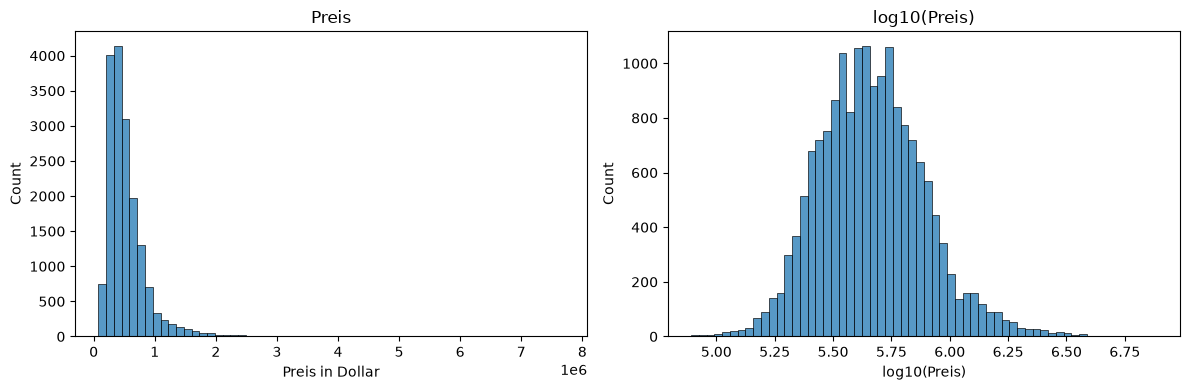

In [6]:
# Plot 1: Wie ist der Preis verteilt?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_train["price"], bins=60, ax=axes[0])
axes[0].set_title("Preis")
axes[0].set_xlabel("Preis in Dollar")
# Mit Logarithmus werden die vielen sehr teuren Häuser zusammengestaucht
sns.histplot(np.log10(df_train["price"]), bins=60, ax=axes[1])
axes[1].set_title("log10(Preis)")
axes[1].set_xlabel("log10(Preis)")
plt.tight_layout()
plt.show()

### Findings – Plot 1: Price distribution
- price is strongly right-skewed 
    - most houses sell between 300k and 650k dollars
    - a few cost several million
- Mean (≈ 541k)
    - the median (450k) because - expensive houses
- log scale the distribution almost symmetric

### Consider log-transforming the target for better fit 

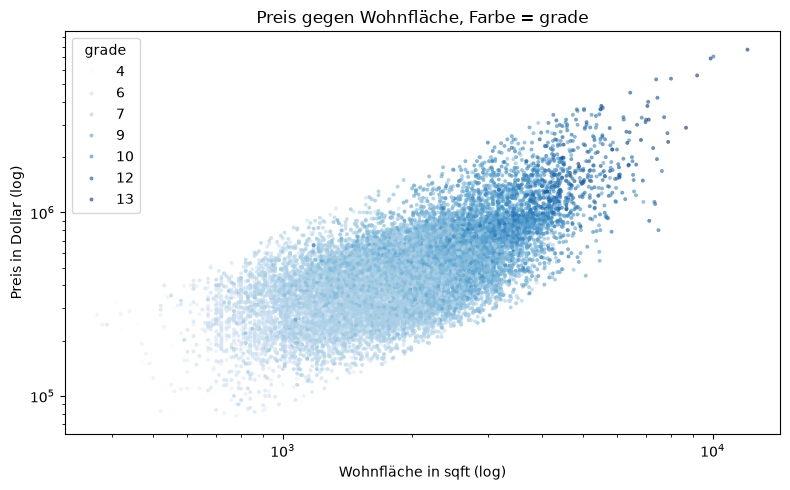

In [7]:
# Plot 2: Preis gegen Wohnfläche, eingefärbt nach Bau-Qualität
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df_train, x="sqft_living", y="price", hue="grade",
                palette="Blues", s=8, alpha=0.6, linewidth=0, ax=ax)
# Beide Achsen logarithmisch, damit die teuren Häuser nicht alles überdecken
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Preis gegen Wohnfläche, Farbe = grade")
ax.set_xlabel("Wohnfläche in sqft (log)")
ax.set_ylabel("Preis in Dollar (log)")
plt.tight_layout()
plt.show()

 ## Findings – Plot 2
- Clear positive relationship
    - larger houses are more expensive 
- Dark points = high grade 
    - bigger houses - better build quality

sqft_living  best single feature for the rule-based baseline

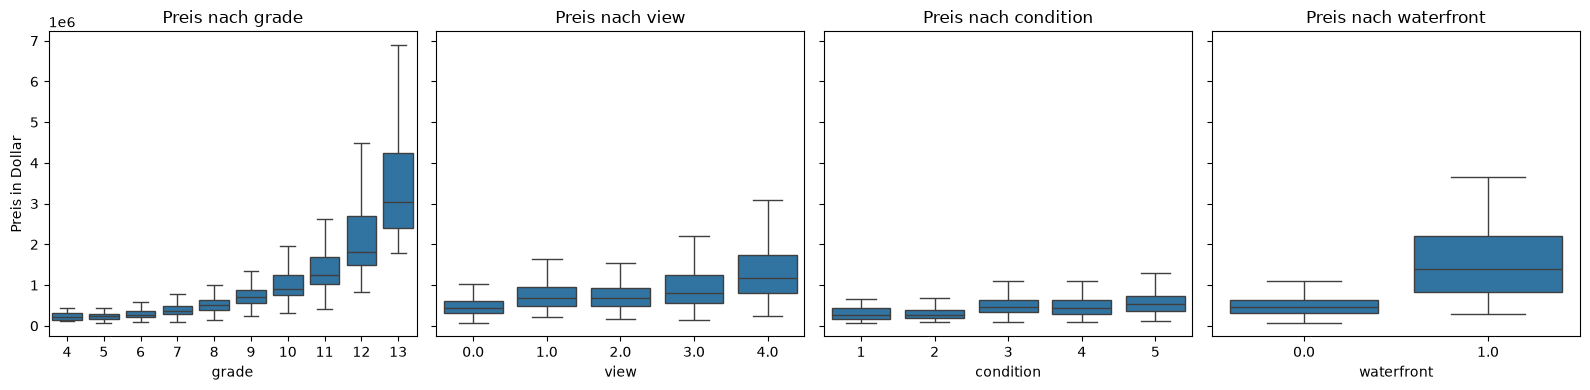

In [8]:
# Plot 3: Preis für jede Stufe der Kategorien mit Rang-Folge
ordinal = ["grade", "view", "condition", "waterfront"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ordinal):
    # showfliers=False blendet Ausreißer aus, damit die Boxen lesbar bleiben
    sns.boxplot(data=df_train, x=col, y="price", color="tab:blue",
                showfliers=False, ax=ax)
    ax.set_title(f"Preis nach {col}")
axes[0].set_ylabel("Preis in Dollar")
plt.tight_layout()
plt.show()

#### Findings – Plot 3
- grade
    - the median rises with every level, from grade 10 rather exponential than linear
- view
    - price rises with a better view
    - the boxes overlap a lot 
- condition 
    - boxes have almost same height 
    - almost no influence on price
- waterfront
    - houses at the water 3 times expensive
    - 0.26 - very few houses are at the water

#### Keep waterfront and view despite low correlation

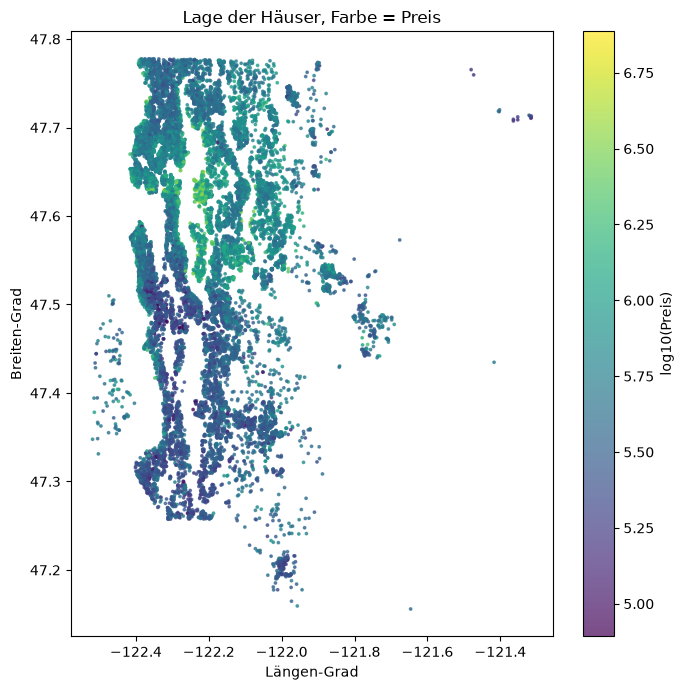

In [9]:
# Plot 4: Wo liegen die teuren Häuser?
fig, ax = plt.subplots(figsize=(7, 7))
points = ax.scatter(df_train["long"], df_train["lat"],
                    c=np.log10(df_train["price"]), cmap="viridis", s=3, alpha=0.7)
fig.colorbar(points, ax=ax, label="log10(Preis)")
ax.set_title("Lage der Häuser, Farbe = Preis")
ax.set_xlabel("Längen-Grad")
ax.set_ylabel("Breiten-Grad")
plt.tight_layout()
plt.show()

#### Findings – Plot 4
- Expensive houses are in the north and center 
- cheaper ones in the south.
- The correlation hardly captures this 
    - location is not linear.

#### Treat zipcode as a category (one-hot encoding), not as a number.

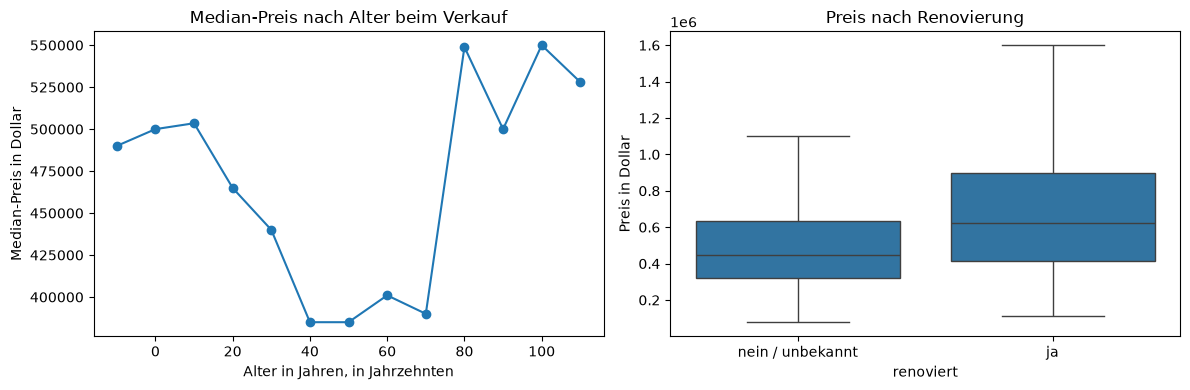

Häuser, die vor dem Baujahr verkauft wurden: 11


In [10]:
# Plot 5: Alter beim Verkauf und Renovierung
age = pd.to_datetime(df_train["date"]).dt.year - df_train["yr_built"]
decade = (age // 10) * 10
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_train.groupby(decade)["price"].median().plot(marker="o", ax=axes[0])
axes[0].set_title("Median-Preis nach Alter beim Verkauf")
axes[0].set_xlabel("Alter in Jahren, in Jahrzehnten")
axes[0].set_ylabel("Median-Preis in Dollar")
renovated = (df_train["yr_renovated"] > 0).map({True: "ja", False: "nein / unbekannt"})
sns.boxplot(x=renovated, y=df_train["price"], color="tab:blue",
            showfliers=False, ax=axes[1])
axes[1].set_title("Preis nach Renovierung")
axes[1].set_xlabel("renoviert")
axes[1].set_ylabel("Preis in Dollar")
plt.tight_layout()
plt.show()
print("Häuser, die vor dem Baujahr verkauft wurden:", (age < 0).sum())

#### Findings – Plot 5
- Age has a non-linear effect
    - new houses relatively expensive
    - houses aged 40–70 years the cheapest
    - very old houses (80+ years) the most expensive
- Renovated houses are more expensive 
- 11 houses sold before construction year (negative age)

##### Create age_at_sale (from date and yr_built)
##### set negative ages to 0
##### Replace yr_renovated with a yes/no column renovated
##### missing values count as "not renovated"
##### Polynomial features can help with the curved age effect

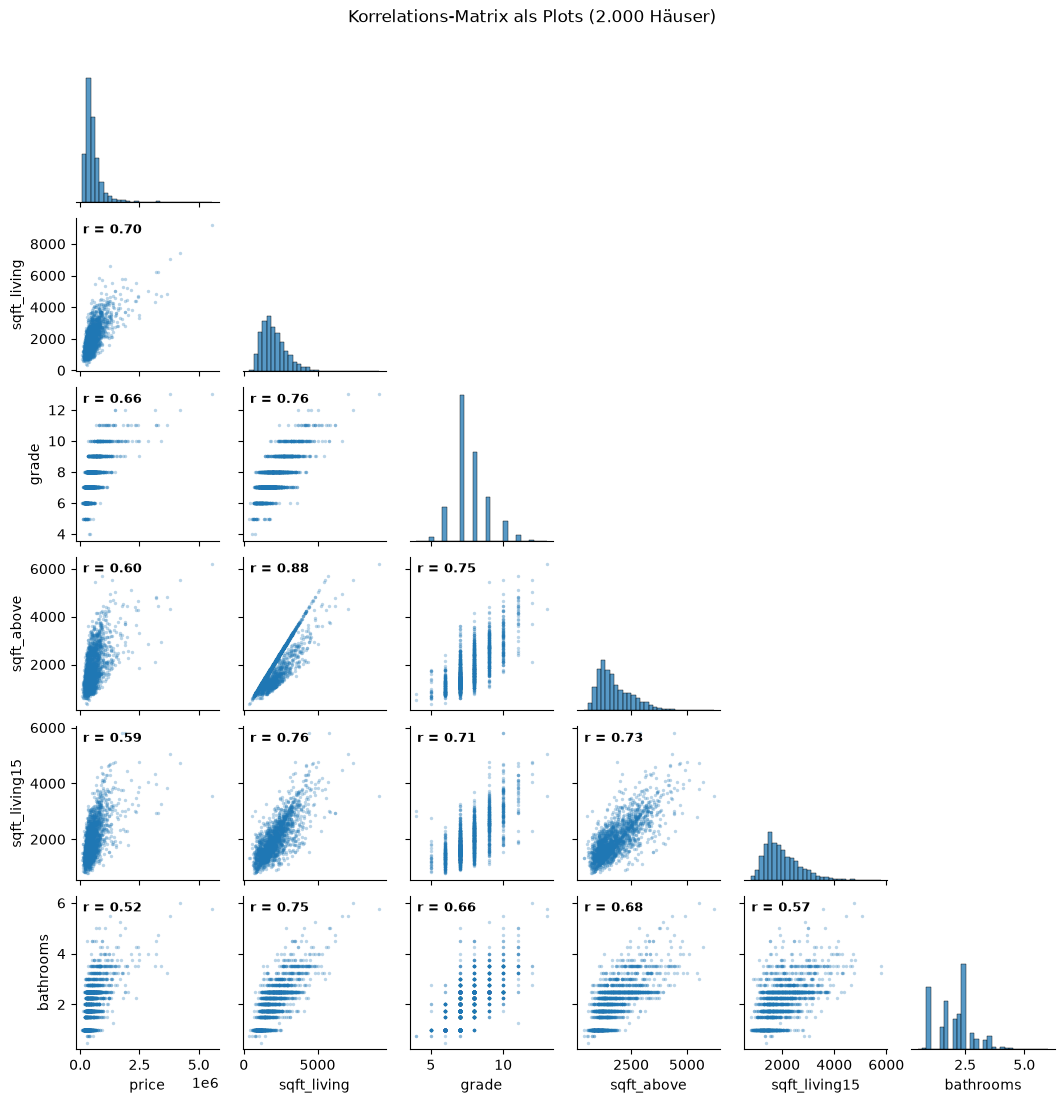

In [11]:
# Plot 6: Korrelations-Matrix als Plots statt Farben
# price und die 5 Spalten mit der stärksten Korrelation zum Preis
cols = ["price", "sqft_living", "grade", "sqft_above", "sqft_living15", "bathrooms"]
# 2.000 zufällige Häuser reichen und machen den Plot schneller
sample = df_train[cols].sample(2000, random_state=42)
grid = sns.pairplot(sample, corner=True, height=1.8,
                    plot_kws={"s": 6, "alpha": 0.3, "linewidth": 0},
                    diag_kws={"bins": 30})
# Die Korrelation r kommt aus allen Trainings-Daten, nicht nur aus der Stichprobe
corr = df_train[cols].corr()
for i, row in enumerate(cols):
    for j, col in enumerate(cols[:i]):
        ax = grid.axes[i, j]
        ax.text(0.05, 0.9, f"r = {corr.loc[row, col]:.2f}",
                transform=ax.transAxes, fontsize=9, fontweight="bold")
grid.figure.suptitle("Korrelations-Matrix als Plots (2.000 Häuser)", y=1.02)
plt.show()

Findings – Plot 6
- All five features rise with price
    - sqft_living most clearly
    - the others show a wider spread
-  features that strongly correlated 
     sqft_living / sqft_above
     sqft_living / grade
     sqft_living15
- sqft_living = sqft_above + sqft_basement 

#### Drop sqft_basement redundant and has missing values

In [ ]:
def prepare(data):
    data = data.copy()
    sale_year = pd.to_datetime(data["date"]).dt.year
    data["age_at_sale"] = (sale_year - data["yr_built"]).clip(lower=0)  # negative Alter -> 0
    data["renovated"] = (data["yr_renovated"] > 0).astype(int)
    return data.drop(columns=["id", "house_id", "id_details", "date",
                              "yr_renovated", "sqft_basement"])
